# 📘 3.6 Interpolation in Machine Learning

### When machine learning behaves like interpolation

In Week 3, we have focused on classical interpolation methods:

* local linear interpolation;
* Newton polynomial interpolation;
* spline interpolation;
* 2D interpolation.

Machine learning regression models can also be used to estimate values between known data points.

This is not always called "interpolation", but the idea is closely related:

> Given training examples, a model learns a function that can be evaluated at new input locations.

For engineering, this often means building a **surrogate model** or **response surface** from experimental or simulation data.

Examples include:

* predicting lift coefficient from angle of attack and Mach number;
* estimating drag from geometry parameters;
* approximating stress from design variables;
* building lookup tables from CFD simulations;
* estimating temperature or pressure fields from sparse measurements.

This notebook introduces how interpolation concepts appear in machine learning, and why extrapolation remains risky.

### 🎯 Learning Objectives

By the end of this notebook, you should be able to:

* explain how interpolation ideas appear in machine learning regression;
* distinguish between exact interpolation and approximate regression;
* describe local, global and probabilistic ML-style interpolators;
* use k-nearest-neighbour regression as a local interpolation method;
* use polynomial ridge regression as a global approximation method;
* use Gaussian process regression to estimate both a mean prediction and uncertainty;
* identify when an ML prediction is outside the training data domain;
* explain why validation data is needed before trusting a machine learning interpolator.

### 🔗 Unit Learning Outcome Alignment

This notebook supports the following MMA3001 learning outcomes:

* **LO1:** Assess the suitability and limitations of machine learning for current and emerging engineering applications.
* **LO2:** Demonstrate effective use of numerical analysis and machine learning tools to develop defensible solutions to open-ended engineering problems.
* **LO3:** Apply appropriate mathematical and numerical techniques to solve common engineering problems, and evaluate program performance, error, stability and accuracy.

### 📚 Sources used in this notebook

The main technical ideas in this notebook are based on:

* scikit-learn API Reference — KNeighborsRegressor  
  https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html

* scikit-learn Example — Nearest Neighbors regression  
  https://scikit-learn.org/stable/auto_examples/neighbors/plot_regression.html

* scikit-learn API Reference — GaussianProcessRegressor  
  https://scikit-learn.org/stable/modules/generated/sklearn.gaussian_process.GaussianProcessRegressor.html

* scikit-learn User Guide — Gaussian Processes  
  https://scikit-learn.org/stable/modules/gaussian_process.html

* scikit-learn Example — Polynomial and Spline interpolation  
  https://scikit-learn.org/stable/auto_examples/linear_model/plot_polynomial_interpolation.html

* scikit-learn User Guide — Cross-validation: evaluating estimator performance  
  https://scikit-learn.org/stable/modules/cross_validation.html

* scikit-learn API Reference — StandardScaler  
  https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

* scikit-learn User Guide — Common pitfalls and recommended practices  
  https://scikit-learn.org/stable/common_pitfalls.html

* SciPy User Guide — Interpolation  
  https://docs.scipy.org/doc/scipy/tutorial/interpolate.html

## 📂 3.6.0 How to use this notebook

This is a **pre-work content notebook**. Run every code cell from top to bottom; no cell
requires editing or typed input.

The separate Week 3 workbook contains the activities to begin in Monday's workshop, continue in Wednesday's practical, and finish during revision at home.

## 📂 3.6.1 Classical interpolation vs machine learning regression

Classical interpolation usually starts with data points and constructs a function that passes exactly through them.

For example, in 1D:

$$
y_i = f(x_i)
$$

and an interpolant satisfies:

$$
\hat{f}(x_i) = y_i
$$

for each known data point.

Machine learning regression usually starts with training data:

$$
\mathbf{X} =
\begin{bmatrix}
x_{11} & x_{12} & \dots & x_{1p} \\
x_{21} & x_{22} & \dots & x_{2p} \\
\vdots & \vdots & \ddots & \vdots \\
x_{n1} & x_{n2} & \dots & x_{np}
\end{bmatrix}
$$

and target values:

$$
\mathbf{y} =
\begin{bmatrix}
y_1 \\
y_2 \\
\vdots \\
y_n
\end{bmatrix}
$$

The model learns a function:

$$
\hat{y} = \hat{f}(\mathbf{x})
$$

where $\mathbf{x}$ may contain several input features.

### Key distinction

Many machine learning regression models are **not exact interpolators**.

They may fit the trend of the data without passing through every training point.

This is useful when data contains noise.

## 📂 3.6.2 Why this matters in engineering

Engineering datasets often contain both structure and uncertainty.

For example, a dataset may contain:

* physical trends;
* measurement noise;
* simulation discretisation error;
* sparse sampling;
* missing data;
* operating limits;
* unmeasured confounding variables.

A machine learning model can be useful if it captures the important trend.

However, a model can also fail if:

* it memorises noisy data;
* it extrapolates beyond the training domain;
* it ignores physics;
* it is trained on biased or incomplete data;
* it is evaluated only on the training data.

> ### ⚠️ Point of note
>
> A machine learning prediction is not automatically valid just because the code returns a number.
>
> You still need to ask:
>
> * Is this query point inside the training data domain?
> * Is it near similar training examples?
> * Has the model been validated?
> * Does the prediction make physical sense?

## 📂 3.6.3 Local, global and probabilistic ML-style interpolators

Different machine learning regression models make different assumptions.

| Model type | Interpolation connection | Key idea |
|---|---|---|
| k-nearest-neighbour regression | Local interpolation | Predict from nearby training points |
| Polynomial ridge regression | Global approximation | Fit a smooth global function using polynomial features |
| Gaussian process regression | Probabilistic interpolation / regression | Predict a mean and uncertainty based on a kernel |
| Decision tree regression | Piecewise-constant approximation | Split feature space into regions |
| Neural network regression | Flexible nonlinear approximation | Learn a function from data through optimisation |

In this notebook, we will use the first three.

Decision tree, support vector and neural network regression are covered in more detail in Week 5.

## 📂 3.6.4 Interpolation and extrapolation in feature space

In 1D interpolation, checking the data range is simple:

$$
x_\text{min} \le x^* \le x_\text{max}
$$

For machine learning, the input often has multiple features.

For example:

$$
\mathbf{x} =
\begin{bmatrix}
\alpha \\
M
\end{bmatrix}
$$

where:

* $\alpha$ is angle of attack;
* $M$ is Mach number.

A query point might be inside the range of each feature but still be far away from the training data.

This is especially important in high-dimensional machine learning.

### Practical checks

Before trusting an ML prediction, check:

1. whether each feature lies inside the training range;
2. whether the query point is close to similar training examples;
3. whether the model has been validated on held-out data;
4. whether the prediction is physically plausible.

In [ ]:
from IPython.display import display
# Core imports for this notebook

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.neighbors import KNeighborsRegressor, NearestNeighbors
from sklearn.linear_model import Ridge
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
from sklearn.metrics import mean_squared_error

pd.set_option("display.precision", 5)

## 📂 3.6.5 Synthetic aerospace example: lift coefficient surrogate model

We will build a machine learning surrogate model for a synthetic aerodynamic coefficient.

The inputs are:

$$
\alpha
$$

and:

$$
M
$$

where:

* $\alpha$ is angle of attack in degrees;
* $M$ is Mach number.

The output is a synthetic lift coefficient:

$$
C_L = f(\alpha, M)
$$

### ⚠️ Data note

This is synthetic teaching data, not measured wind tunnel data.

It is designed to have a plausible engineering shape while keeping the notebook self-contained.

Because the true function is known in this notebook, we can calculate errors directly. In real engineering work, the true function is usually unknown.

In [ ]:
def synthetic_lift_coefficient(alpha_deg, mach):
    """
    Synthetic lift coefficient function for teaching ML-style interpolation.

    This is not measured aerodynamic data.

    Parameters
    ----------
    alpha_deg : array-like
        Angle of attack in degrees.

    mach : array-like
        Mach number.

    Returns
    -------
    array-like
        Synthetic lift coefficient.
    """
    alpha_deg = np.asarray(alpha_deg, dtype=float)
    mach = np.asarray(mach, dtype=float)

    alpha_rad = np.deg2rad(alpha_deg)

    # Approximate low-alpha lift trend with a Mach-dependent factor.
    mach_factor = 1.0 + 0.25 * (mach - 0.5)
    pre_stall_lift = 2 * np.pi * alpha_rad * mach_factor

    # Smooth saturation so the coefficient does not grow forever.
    saturated_lift = 1.25 * np.tanh(pre_stall_lift / 1.25)

    # Synthetic post-stall-like drop.
    stall_drop = 0.022 * np.maximum(alpha_deg - 12.0, 0.0) ** 2 * (1.0 + 0.4 * mach)

    # Mild Mach-dependent variation.
    mach_wave = 0.20 * np.sin(3 * np.pi * mach) * (1.0 - 0.02 * alpha_deg)

    return saturated_lift - stall_drop + mach_wave


def rmse(y_true, y_pred):
    """
    Root mean squared error.
    """
    return np.sqrt(mean_squared_error(y_true, y_pred))

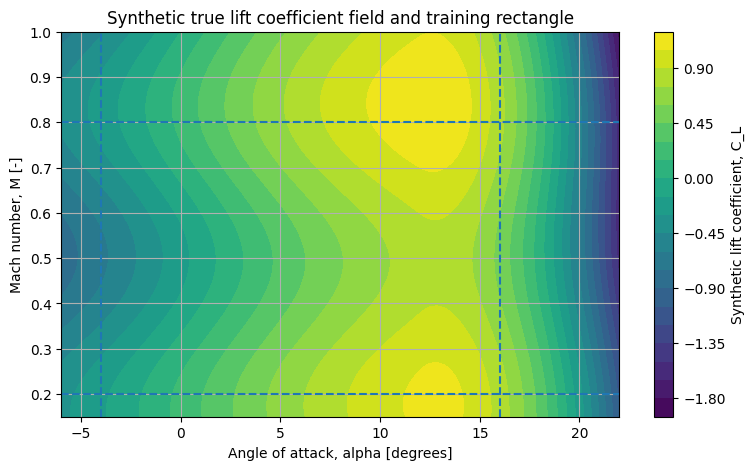

In [ ]:
# Define the training domain.

alpha_min = -4.0
alpha_max = 16.0

mach_min = 0.20
mach_max = 0.80

# Create a dense grid only for plotting and teaching error checks.

alpha_plot = np.linspace(-6, 22, 160)
mach_plot = np.linspace(0.15, 1.00, 120)

A_plot, M_plot = np.meshgrid(alpha_plot, mach_plot, indexing="ij")

CL_true_plot = synthetic_lift_coefficient(A_plot, M_plot)

fig, ax = plt.subplots(figsize=(9, 5))

contour = ax.contourf(A_plot, M_plot, CL_true_plot, levels=20)
fig.colorbar(contour, ax=ax, label="Synthetic lift coefficient, C_L")

ax.axvline(alpha_min, linestyle="--")
ax.axvline(alpha_max, linestyle="--")
ax.axhline(mach_min, linestyle="--")
ax.axhline(mach_max, linestyle="--")

ax.set_xlabel("Angle of attack, alpha [degrees]")
ax.set_ylabel("Mach number, M [-]")
ax.set_title("Synthetic true lift coefficient field and training rectangle")
ax.grid(True)

plt.show()

### 🧠 What should you notice?

The dashed rectangle marks the region where training data will be collected.

Predictions inside this rectangle are closer to interpolation.

Predictions outside this rectangle are closer to extrapolation.

### ⚠️ Point of note

In this notebook, the true function is known because we created it.

In real engineering work, you would usually only have measurements or simulation outputs.

In [ ]:
# Generate noisy training data inside the training domain.

rng = np.random.default_rng(314)

n_train = 90
noise_std = 0.045

alpha_train = rng.uniform(alpha_min, alpha_max, n_train)
mach_train = rng.uniform(mach_min, mach_max, n_train)

X_train = np.column_stack([alpha_train, mach_train])

y_train_true = synthetic_lift_coefficient(alpha_train, mach_train)
y_train = y_train_true + rng.normal(0, noise_std, size=n_train)

training_data = pd.DataFrame({
    "alpha_deg": alpha_train,
    "mach": mach_train,
    "CL_measured": y_train,
    "CL_true_for_teaching_only": y_train_true
})

training_data.head()

,alpha_deg,mach,CL_measured,CL_true_for_teaching_only
0,14.45084,0.36954,0.82254,0.85266
1,10.25296,0.31914,0.89380,0.89076
2,11.04091,0.73960,1.09474,1.06457
3,7.40160,0.25771,0.77804,0.79159
4,-1.40164,0.21582,0.05993,0.04177


In [ ]:
# Create validation points inside the training domain.

n_validation = 200

alpha_validation = rng.uniform(alpha_min, alpha_max, n_validation)
mach_validation = rng.uniform(mach_min, mach_max, n_validation)

X_validation = np.column_stack([alpha_validation, mach_validation])

y_validation_true = synthetic_lift_coefficient(alpha_validation, mach_validation)

# Create out-of-domain challenge points.

alpha_extrap = rng.uniform(17.0, 24.0, 80)
mach_extrap = rng.uniform(0.85, 1.05, 80)

X_extrap = np.column_stack([alpha_extrap, mach_extrap])

y_extrap_true = synthetic_lift_coefficient(alpha_extrap, mach_extrap)

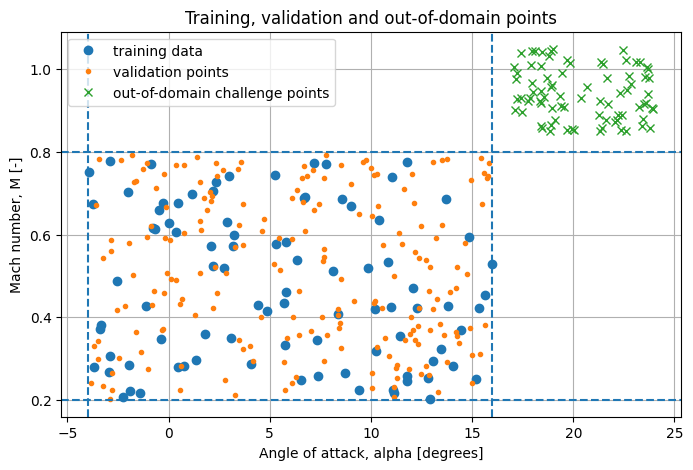

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(alpha_train, mach_train, "o", label="training data")
ax.plot(alpha_validation, mach_validation, ".", label="validation points")
ax.plot(alpha_extrap, mach_extrap, "x", label="out-of-domain challenge points")

ax.axvline(alpha_min, linestyle="--")
ax.axvline(alpha_max, linestyle="--")
ax.axhline(mach_min, linestyle="--")
ax.axhline(mach_max, linestyle="--")

ax.set_xlabel("Angle of attack, alpha [degrees]")
ax.set_ylabel("Mach number, M [-]")
ax.set_title("Training, validation and out-of-domain points")
ax.grid(True)
ax.legend()

plt.show()

## 📂 3.6.6 Building three ML-style interpolators

We will compare three models.

### 1. k-nearest-neighbour regression

KNN regression predicts from nearby training examples.

This is strongly connected to local interpolation.

### 2. Polynomial ridge regression

Polynomial ridge regression creates polynomial features and fits a regularised global model.

This behaves more like a global curve-fitting method.

### 3. Gaussian process regression

Gaussian process regression uses a kernel to define similarity between points.

It can return both:

* a predicted mean;
* a predictive standard deviation.

The standard deviation can help identify regions where the model is less certain.

In [ ]:
# KNN with k=1.
# This is highly local and can exactly reproduce training targets at training locations.

knn_1 = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsRegressor(n_neighbors=1))
])

# KNN with more neighbours and distance weighting.
# This is still local, but smoother than k=1.

knn_9 = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsRegressor(n_neighbors=9, weights="distance"))
])

# Global polynomial ridge model.
# StandardScaler is used before PolynomialFeatures so that the polynomial features
# are built from scaled inputs.

polynomial_ridge = Pipeline([
    ("scale", StandardScaler()),
    ("poly", PolynomialFeatures(degree=3, include_bias=False)),
    ("model", Ridge(alpha=1.0))
])

# Gaussian process regression.
# We scale the inputs manually so that the RBF kernel length scales are easier to interpret.

gpr_scaler = StandardScaler().fit(X_train)
X_train_scaled_for_gpr = gpr_scaler.transform(X_train)

gpr_kernel = (
    ConstantKernel(1.0)
    * RBF(length_scale=[1.0, 1.0])
    + WhiteKernel(noise_level=noise_std**2)
)

gpr = GaussianProcessRegressor(
    kernel=gpr_kernel,
    normalize_y=True,
    optimizer=None,
    random_state=0
)

In [ ]:
# Fit the models.

models = {
    "KNN, k=1": knn_1,
    "KNN, k=9, distance weighted": knn_9,
    "degree-3 polynomial ridge": polynomial_ridge
}

for model in models.values():
    model.fit(X_train, y_train)

gpr.fit(X_train_scaled_for_gpr, y_train)


def gpr_predict(X, return_std=False):
    """
    Predict using the Gaussian process model after applying the input scaler.
    """
    X_scaled = gpr_scaler.transform(X)
    return gpr.predict(X_scaled, return_std=return_std)

## 📂 3.6.7 Evaluating models inside and outside the training domain

We will compare errors on three datasets:

| Dataset | Meaning |
|---|---|
| Training data | Noisy data used to fit the model |
| Validation data | New points inside the training domain |
| Out-of-domain challenge data | Points outside the training domain |

The validation data is the most useful for estimating how well the model interpolates within the training domain.

The out-of-domain challenge data is included to show why extrapolation is risky.

In [ ]:
error_rows = []

for name, model in models.items():
    error_rows.append({
        "model": name,
        "training_RMSE_against_noisy_data": rmse(y_train, model.predict(X_train)),
        "validation_RMSE_inside_domain": rmse(y_validation_true, model.predict(X_validation)),
        "extrapolation_RMSE_outside_domain": rmse(y_extrap_true, model.predict(X_extrap))
    })

gpr_train = gpr_predict(X_train)
gpr_validation = gpr_predict(X_validation)
gpr_extrap = gpr_predict(X_extrap)

error_rows.append({
    "model": "Gaussian process regression",
    "training_RMSE_against_noisy_data": rmse(y_train, gpr_train),
    "validation_RMSE_inside_domain": rmse(y_validation_true, gpr_validation),
    "extrapolation_RMSE_outside_domain": rmse(y_extrap_true, gpr_extrap)
})

error_table = pd.DataFrame(error_rows)

error_table

,model,training_RMSE_against_noisy_data,validation_RMSE_inside_domain,extrapolation_RMSE_outside_domain
0,"KNN, k=1",0.00000,0.09370,2.38179
1,"KNN, k=9, distance weighted",0.00000,0.07594,2.25349
2,degree-3 polynomial ridge,0.05551,0.04707,2.01792
3,Gaussian process regression,0.03506,0.04829,1.95826


### 🧠 What should you notice?

The model with the lowest training error is not necessarily the best model for new data.

The out-of-domain error is usually much larger than the validation error.

This is the same warning that appeared throughout Week 3:

> Interpolation inside a supported domain is usually more defensible than extrapolation outside it.

### ⚠️ Engineering warning

A machine learning model can produce a number far outside the training domain.

That number may be smooth, precise-looking and completely misleading.

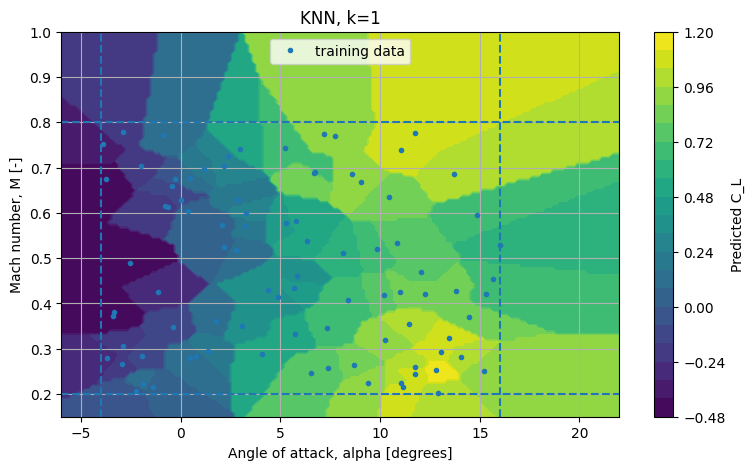

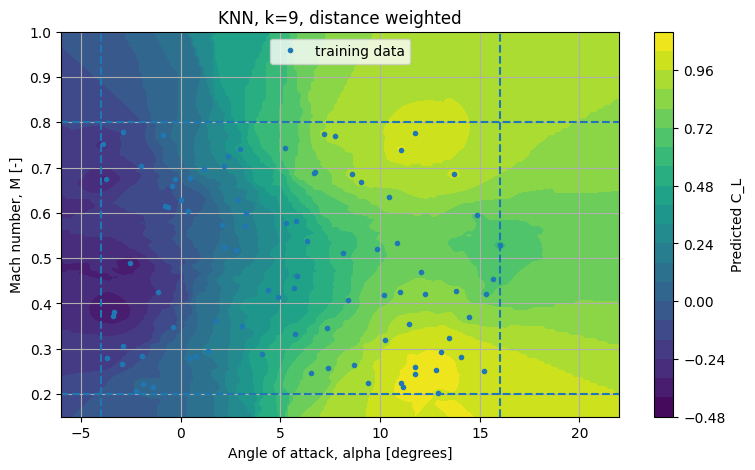

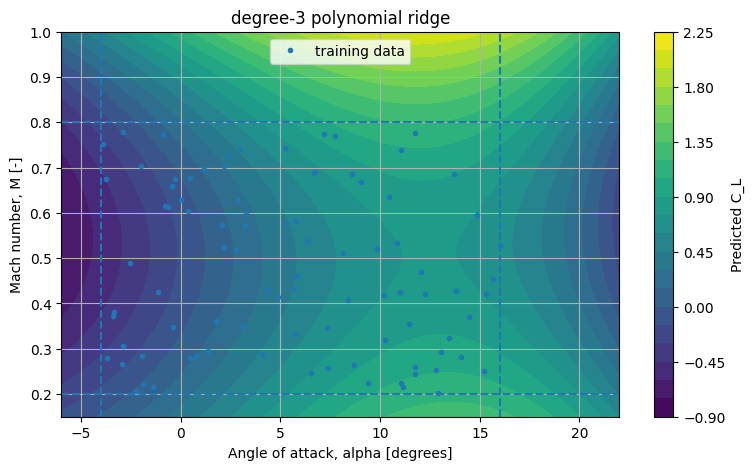

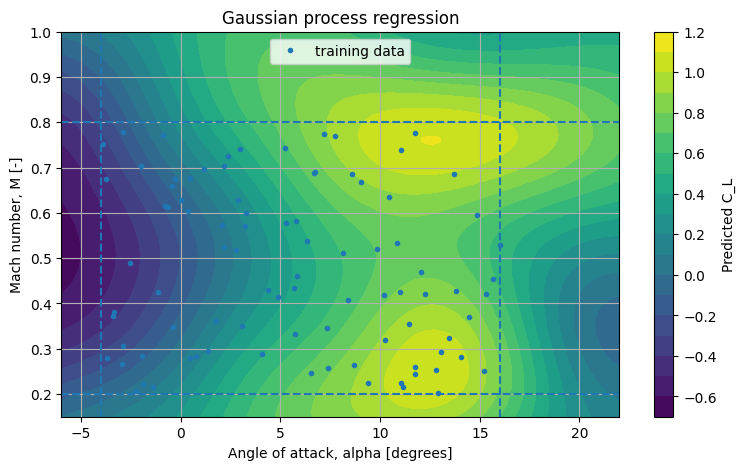

In [ ]:
# Plot predictions from each model over a wider region than the training domain.

X_plot = np.column_stack([A_plot.ravel(), M_plot.ravel()])

surface_predictors = {
    "KNN, k=1": lambda X: knn_1.predict(X),
    "KNN, k=9, distance weighted": lambda X: knn_9.predict(X),
    "degree-3 polynomial ridge": lambda X: polynomial_ridge.predict(X),
    "Gaussian process regression": lambda X: gpr_predict(X)
}

for name, predict_function in surface_predictors.items():
    CL_predicted = predict_function(X_plot).reshape(A_plot.shape)

    fig, ax = plt.subplots(figsize=(9, 5))

    contour = ax.contourf(A_plot, M_plot, CL_predicted, levels=20)
    fig.colorbar(contour, ax=ax, label="Predicted C_L")

    ax.plot(alpha_train, mach_train, "o", markersize=3, label="training data")

    ax.axvline(alpha_min, linestyle="--")
    ax.axvline(alpha_max, linestyle="--")
    ax.axhline(mach_min, linestyle="--")
    ax.axhline(mach_max, linestyle="--")

    ax.set_xlabel("Angle of attack, alpha [degrees]")
    ax.set_ylabel("Mach number, M [-]")
    ax.set_title(name)
    ax.grid(True)
    ax.legend()

    plt.show()

### 🧠 Interpretation

The KNN models behave locally.

The polynomial ridge model behaves globally.

The Gaussian process model gives a smooth prediction based on the chosen kernel.

None of these models should be trusted automatically outside the training rectangle.

### ⚠️ Point of note

Do not choose an ML model only because its contour plot looks smooth.

A smooth plot can hide poor extrapolation, sparse data coverage or unrealistic assumptions.

## 📂 3.6.8 Exact interpolation vs approximate regression

Some ML models can behave like exact interpolators at training points.

For example, KNN with $k=1$ predicts the target value of the nearest training point.

If the query location is exactly a training location, the nearest point is itself.

Other models may not pass exactly through every training point because they are designed to smooth, regularise or account for noise.

This can be a strength when data is noisy.

In [ ]:
# Choose one exact training point.

nearest_train_index = 10

exact_query = X_train[[nearest_train_index]]

exact_training_point_table = pd.DataFrame({
    "alpha_deg": exact_query[:, 0],
    "mach": exact_query[:, 1],
    "measured_CL": y_train[[nearest_train_index]],
    "KNN_k1_prediction": knn_1.predict(exact_query),
    "KNN_k9_prediction": knn_9.predict(exact_query),
    "polynomial_ridge_prediction": polynomial_ridge.predict(exact_query),
    "gpr_prediction": gpr_predict(exact_query)
})

exact_training_point_table

,alpha_deg,mach,measured_CL,KNN_k1_prediction,KNN_k9_prediction,polynomial_ridge_prediction,gpr_prediction
0,3.08417,0.35061,0.33491,0.33491,0.33491,0.2822,0.29053


### 🧠 What should you notice?

KNN with $k=1$ should reproduce the measured training value exactly.

The other models may produce similar but not identical values.

This is not necessarily a problem.

If the training data contains noise, exact interpolation may be less useful than a model that captures the underlying trend.

## 📂 3.6.9 The effect of the number of neighbours in KNN

The value of $k$ controls how local the KNN model is.

| Small $k$ | Large $k$ |
|---|---|
| More local | More averaged |
| More flexible | Smoother |
| Can memorise noise | Can underfit |
| Sensitive to individual points | Less sensitive to individual points |

We will fit KNN models for different values of $k$ and compare training and validation error.

In [ ]:
k_values = np.arange(1, 31)

knn_rows = []

for k in k_values:
    knn_model = Pipeline([
        ("scale", StandardScaler()),
        ("model", KNeighborsRegressor(n_neighbors=int(k), weights="uniform"))
    ])

    knn_model.fit(X_train, y_train)

    knn_rows.append({
        "k": int(k),
        "training_RMSE": rmse(y_train, knn_model.predict(X_train)),
        "validation_RMSE": rmse(y_validation_true, knn_model.predict(X_validation))
    })

knn_k_table = pd.DataFrame(knn_rows)

knn_k_table.head()

,k,training_RMSE,validation_RMSE
0,1,0.00000,0.09370
1,2,0.05872,0.07756
2,3,0.06194,0.08048
3,4,0.07075,0.08432
4,5,0.07719,0.08466


In [ ]:
best_k_row = knn_k_table.loc[knn_k_table["validation_RMSE"].idxmin()]

print(f"Best k by validation RMSE: {int(best_k_row['k'])}")
print(f"Validation RMSE: {best_k_row['validation_RMSE']:.5f}")

Best k by validation RMSE: 2
Validation RMSE: 0.07756


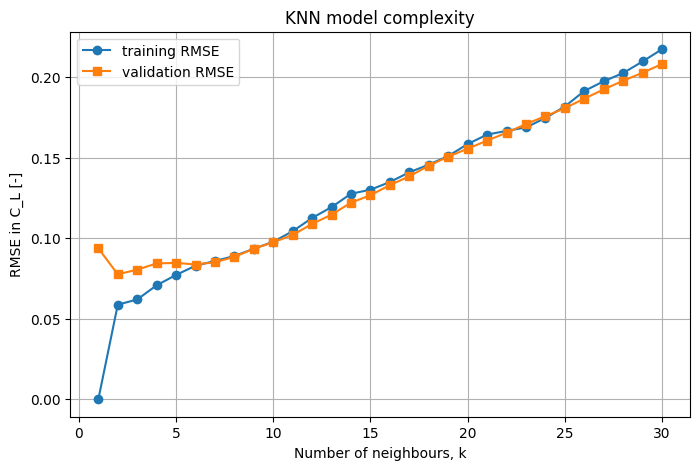

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(knn_k_table["k"], knn_k_table["training_RMSE"], "o-", label="training RMSE")
ax.plot(knn_k_table["k"], knn_k_table["validation_RMSE"], "s-", label="validation RMSE")

ax.set_xlabel("Number of neighbours, k")
ax.set_ylabel("RMSE in C_L [-]")
ax.set_title("KNN model complexity")
ax.grid(True)
ax.legend()

plt.show()

### 🧠 What should you notice?

When $k=1$, the model is very flexible and can reproduce the training data exactly.

As $k$ increases, the model averages over more neighbours.

This can reduce sensitivity to noise, but too much averaging can remove real structure.

This is similar to the underfitting-overfitting trade-off from Notebook 3.2.

## 📂 3.6.10 Feature scaling and distance-based interpolation

KNN uses distances between points.

That means feature scaling matters.

For example, angle of attack is measured in degrees and Mach number is dimensionless.

If one feature has a much larger numerical range than another, it can dominate the distance calculation.

`StandardScaler` transforms each feature using:

$$
z = \frac{x - \mu}{s}
$$

where $\mu$ is the mean of the training samples and $s$ is the standard deviation of the training samples.

### ⚠️ Point of note

Scaling is not just a coding detail.

It changes which training points are considered "nearby".

In [ ]:
knn_without_scaling = KNeighborsRegressor(
    n_neighbors=9,
    weights="distance"
)

knn_with_scaling = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsRegressor(n_neighbors=9, weights="distance"))
])

knn_without_scaling.fit(X_train, y_train)
knn_with_scaling.fit(X_train, y_train)

scaling_table = pd.DataFrame({
    "model": [
        "KNN without feature scaling",
        "KNN with StandardScaler"
    ],
    "validation_RMSE": [
        rmse(y_validation_true, knn_without_scaling.predict(X_validation)),
        rmse(y_validation_true, knn_with_scaling.predict(X_validation))
    ]
})

scaling_table

,model,validation_RMSE
0,KNN without feature scaling,0.11939
1,KNN with StandardScaler,0.07594


### 🧠 Interpretation

Feature scaling changes the distance calculation used by KNN.

In this synthetic example, scaling should help because both angle of attack and Mach number affect the target.

In real engineering work, you should think carefully about distance metrics.

Two points can be numerically close but physically different, or numerically far apart but physically similar after appropriate nondimensionalisation.

## 📂 3.6.11 Checking whether an ML prediction is supported by training data

For a two-feature model, a simple first check is the training rectangle:

$$
\alpha_\text{min} \le \alpha^* \le \alpha_\text{max}
$$

and:

$$
M_\text{min} \le M^* \le M_\text{max}
$$

But this is not enough.

A point can be inside the rectangle but still far from nearby training examples.

We will use nearest-neighbour distance in scaled feature space as a simple support check.

In [ ]:
# Build a nearest-neighbour model for checking training data support.

coverage_scaler = StandardScaler().fit(X_train)

X_train_scaled = coverage_scaler.transform(X_train)

nearest_model = NearestNeighbors(n_neighbors=2)
nearest_model.fit(X_train_scaled)

# Distance from each training point to its nearest other training point.
train_distances, train_indices = nearest_model.kneighbors(X_train_scaled)
train_nearest_distances = train_distances[:, 1]

# This threshold is a simple teaching heuristic, not a universal rule.
distance_threshold = 2.0 * np.percentile(train_nearest_distances, 95)

print(f"Support distance threshold: {distance_threshold:.3f}")

Support distance threshold: 0.796


In [ ]:
def training_support_table(query_conditions):
    """
    Create a support table for ML predictions.

    Parameters
    ----------
    query_conditions : ndarray with shape (n_points, 2)
        Query points arranged as [alpha_deg, mach].

    Returns
    -------
    pandas.DataFrame
        Table showing whether the point is inside the training rectangle
        and how far it is from the nearest training example.
    """
    query_conditions = np.asarray(query_conditions, dtype=float)

    query_scaled = coverage_scaler.transform(query_conditions)

    distances, indices = nearest_model.kneighbors(
        query_scaled,
        n_neighbors=1
    )

    inside_rectangle = (
        (query_conditions[:, 0] >= alpha_min) &
        (query_conditions[:, 0] <= alpha_max) &
        (query_conditions[:, 1] >= mach_min) &
        (query_conditions[:, 1] <= mach_max)
    )

    support_label = np.where(
        ~inside_rectangle,
        "outside training rectangle",
        np.where(
            distances.ravel() <= distance_threshold,
            "inside and near training data",
            "inside rectangle but sparse"
        )
    )

    gpr_mean, gpr_std = gpr_predict(
        query_conditions,
        return_std=True
    )

    return pd.DataFrame({
        "alpha_deg": query_conditions[:, 0],
        "mach": query_conditions[:, 1],
        "support_label": support_label,
        "nearest_training_distance_scaled": distances.ravel(),
        "gpr_mean_CL": gpr_mean,
        "gpr_std_CL": gpr_std
    })

In [ ]:
engineering_queries = np.array([
    [4.0, 0.40],
    [14.0, 0.75],
    [20.0, 0.95]
], dtype=float)

support_results = training_support_table(engineering_queries)

support_results

,alpha_deg,mach,support_label,nearest_training_distance_scaled,gpr_mean_CL,gpr_std_CL
0,4.0,0.40,inside and near training data,0.16889,0.30500,0.02304
1,14.0,0.75,inside and near training data,0.36417,1.08555,0.04747
2,20.0,0.95,outside training rectangle,1.70845,0.53704,0.40629


### 🧠 What should you notice?

The out-of-domain query has a larger distance from the training data.

The Gaussian process standard deviation should also tend to increase away from the training data.

This does not prove the Gaussian process uncertainty is perfectly calibrated.

It is a useful warning signal, not a guarantee.

### ⚠️ Engineering warning

A support check should be included before using an ML model inside an engineering calculation.

At minimum, report whether the requested prediction is inside the training data range.

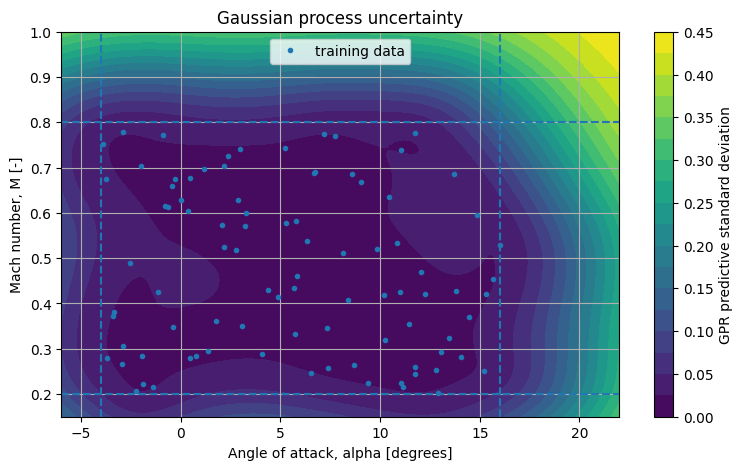

In [ ]:
# Visualise Gaussian process predictive uncertainty.

gpr_mean_grid, gpr_std_grid = gpr_predict(
    X_plot,
    return_std=True
)

gpr_std_grid = gpr_std_grid.reshape(A_plot.shape)

fig, ax = plt.subplots(figsize=(9, 5))

contour = ax.contourf(A_plot, M_plot, gpr_std_grid, levels=20)
fig.colorbar(contour, ax=ax, label="GPR predictive standard deviation")

ax.plot(alpha_train, mach_train, "o", markersize=3, label="training data")

ax.axvline(alpha_min, linestyle="--")
ax.axvline(alpha_max, linestyle="--")
ax.axhline(mach_min, linestyle="--")
ax.axhline(mach_max, linestyle="--")

ax.set_xlabel("Angle of attack, alpha [degrees]")
ax.set_ylabel("Mach number, M [-]")
ax.set_title("Gaussian process uncertainty")
ax.grid(True)
ax.legend()

plt.show()

## 📂 3.6.12 Method selection summary

| Situation | Possible model | Comment |
|---|---|---|
| Need a simple local interpolator | KNN regression | Easy to understand, sensitive to scaling and data density |
| Need a smooth global response surface | Polynomial ridge regression | Useful for simple trends, may extrapolate poorly |
| Need uncertainty estimates | Gaussian process regression | Useful for small datasets, can become expensive for large or high-dimensional datasets |
| Need interpretability through rules | Decision tree regression | Covered in Week 5 |
| Need flexible nonlinear modelling | Neural network regression | Covered in Week 5 |

### Practical rule

Do not start by asking, "Which ML model should I use?"

Start by asking:

1. What features are available?
2. What is the training domain?
3. Is the data noisy?
4. Is the model being used for interpolation or extrapolation?
5. How will the prediction be validated?
6. What error would be acceptable for the engineering decision?

## 📂 3.6.13 Worked extension — choose a model and make predictions

Change the query conditions and model name below.

Available model names are:

* `KNN, k=1`
* `KNN, k=9, distance weighted`
* `degree-3 polynomial ridge`
* `Gaussian process regression`

### Questions

1. Which model did you choose?
2. Are your query points inside the training rectangle?
3. Which query point has the largest absolute error?
4. Which query point would you be least comfortable reporting in an engineering calculation?
5. Would your answer change if you did not know the true function?

In [ ]:
# Demonstration setting: Change the model name and query conditions.

student_model_name = "KNN, k=9, distance weighted"

student_query_conditions = np.array([
    [2.0, 0.30],
    [10.0, 0.65],
    [18.0, 0.90]
], dtype=float)

if student_model_name == "Gaussian process regression":
    student_predictions = gpr_predict(student_query_conditions)
else:
    student_predictions = models[student_model_name].predict(student_query_conditions)

student_true_values = synthetic_lift_coefficient(
    student_query_conditions[:, 0],
    student_query_conditions[:, 1]
)

student_results = pd.DataFrame({
    "alpha_deg": student_query_conditions[:, 0],
    "mach": student_query_conditions[:, 1],
    "support_label": training_support_table(student_query_conditions)["support_label"],
    "student_prediction_CL": student_predictions,
    "true_for_teaching_only": student_true_values
})

student_results["absolute_error"] = np.abs(
    student_results["student_prediction_CL"] - student_results["true_for_teaching_only"]
)

student_results

,alpha_deg,mach,support_label,student_prediction_CL,true_for_teaching_only,absolute_error
0,2.0,0.30,inside and near training data,0.19599,0.26578,0.06979
1,10.0,0.65,inside and near training data,0.85708,0.87650,0.01942
2,18.0,0.90,outside training rectangle,0.94095,0.20129,0.73966


## 📂 3.6.14 Worked extension — investigate training data coverage

In this activity, you will change the number of training points and refit a KNN model.

Try values such as:

* 20 training points;
* 50 training points;
* 100 training points;
* 200 training points.

### Questions

1. What happens to validation error as the number of training points increases?
2. Does the out-of-domain error improve as much as the validation error?
3. Why might adding more data inside the original training rectangle not solve extrapolation problems?
4. Where would you collect additional data if you cared about predictions at high angle of attack and high Mach number?

In [ ]:
# Demonstration setting: Change this value and rerun the cell.

student_n_train = 50

rng_student = np.random.default_rng(2026)

student_alpha_train = rng_student.uniform(alpha_min, alpha_max, student_n_train)
student_mach_train = rng_student.uniform(mach_min, mach_max, student_n_train)

student_X_train = np.column_stack([
    student_alpha_train,
    student_mach_train
])

student_y_train_true = synthetic_lift_coefficient(
    student_alpha_train,
    student_mach_train
)

student_y_train = student_y_train_true + rng_student.normal(
    0,
    noise_std,
    size=student_n_train
)

student_knn = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsRegressor(n_neighbors=9, weights="distance"))
])

student_knn.fit(student_X_train, student_y_train)

student_training_rmse = rmse(
    student_y_train,
    student_knn.predict(student_X_train)
)

student_validation_rmse = rmse(
    y_validation_true,
    student_knn.predict(X_validation)
)

student_extrap_rmse = rmse(
    y_extrap_true,
    student_knn.predict(X_extrap)
)

student_coverage_error_table = pd.DataFrame({
    "n_training_points": [student_n_train],
    "training_RMSE_against_noisy_data": [student_training_rmse],
    "validation_RMSE_inside_domain": [student_validation_rmse],
    "extrapolation_RMSE_outside_domain": [student_extrap_rmse]
})

student_coverage_error_table

,n_training_points,training_RMSE_against_noisy_data,validation_RMSE_inside_domain,extrapolation_RMSE_outside_domain
0,50,0.0,0.13724,2.24498


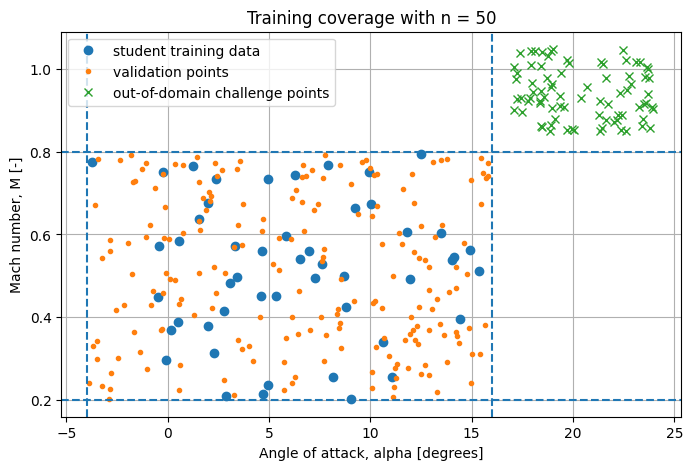

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(student_alpha_train, student_mach_train, "o", label="student training data")
ax.plot(alpha_validation, mach_validation, ".", label="validation points")
ax.plot(alpha_extrap, mach_extrap, "x", label="out-of-domain challenge points")

ax.axvline(alpha_min, linestyle="--")
ax.axvline(alpha_max, linestyle="--")
ax.axhline(mach_min, linestyle="--")
ax.axhline(mach_max, linestyle="--")

ax.set_xlabel("Angle of attack, alpha [degrees]")
ax.set_ylabel("Mach number, M [-]")
ax.set_title(f"Training coverage with n = {student_n_train}")
ax.grid(True)
ax.legend()

plt.show()

## 📂 3.6.15 Worked extension — compare AI-generated code with documentation

Use Gemini in Colab or another approved AI tool.

> ### 🗣️ AI Prompt
>
> I am studying numerical methods and machine learning for third-year engineering. Explain how machine learning regression can behave like interpolation. Compare k-nearest-neighbour regression, polynomial ridge regression and Gaussian process regression using an aerodynamic coefficient example. Include warnings about feature scaling, validation data, extrapolation outside the training domain and uncertainty estimates. Do not invent measured experimental data.

### 🧠 Critique task

After reading the AI response, answer these questions:

1. Did the AI clearly distinguish interpolation from extrapolation?
2. Did the AI explain that many ML regressors do not pass exactly through training data?
3. Did the AI mention feature scaling for distance-based methods?
4. Did the AI explain why validation data is needed?
5. Did the AI overstate the reliability of Gaussian process uncertainty?
6. Did the AI recommend any checks that could be performed using code?
7. What would you change to make the explanation more useful for engineering work?

### ⚠️ Point of note

AI-generated ML code often runs, but that does not mean it is a defensible engineering workflow.

Always check:

* the data domain;
* preprocessing steps;
* validation method;
* units and scaling;
* prediction error;
* physical plausibility.

## 📂 3.6.16 Recommended resources

### Reading

* scikit-learn API Reference — KNeighborsRegressor  
  https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html

* scikit-learn Example — Nearest Neighbors regression  
  https://scikit-learn.org/stable/auto_examples/neighbors/plot_regression.html

* scikit-learn API Reference — GaussianProcessRegressor  
  https://scikit-learn.org/stable/modules/generated/sklearn.gaussian_process.GaussianProcessRegressor.html

* scikit-learn User Guide — Gaussian Processes  
  https://scikit-learn.org/stable/modules/gaussian_process.html

* scikit-learn Example — Polynomial and Spline interpolation  
  https://scikit-learn.org/stable/auto_examples/linear_model/plot_polynomial_interpolation.html

* scikit-learn User Guide — Cross-validation: evaluating estimator performance  
  https://scikit-learn.org/stable/modules/cross_validation.html

* scikit-learn API Reference — StandardScaler  
  https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

* scikit-learn User Guide — Common pitfalls and recommended practices  
  https://scikit-learn.org/stable/common_pitfalls.html

* SciPy User Guide — Interpolation  
  https://docs.scipy.org/doc/scipy/tutorial/interpolate.html

### Videos

* StatQuest — K-nearest neighbours  
  https://www.youtube.com/results?search_query=StatQuest+k+nearest+neighbors+regression

* Gaussian process regression introduction  
  https://www.youtube.com/results?search_query=Gaussian+process+regression+introduction

* Machine learning model validation  
  https://www.youtube.com/results?search_query=machine+learning+train+validation+test+set+explained

## 📂 3.6.17 Engineering workflow and summary

Machine learning regression extends many of the ideas introduced through classical interpolation. Both use known data to estimate values at new inputs, but machine learning models do not necessarily pass through every training observation.

The methods examined in this notebook represent three different modelling approaches:

- **K-nearest-neighbour regression** is a local, distance-based method influenced by nearby training observations.

- **Polynomial ridge regression** is a global approximation method that uses the complete training dataset and regularisation.

- **Gaussian-process regression** is a probabilistic method that provides a mean prediction and a model-based estimate of uncertainty.

The main lessons from this notebook are:

- exact interpolation and approximate regression solve related but different problems;

- local, global and probabilistic models make different assumptions about the underlying relationship;

- feature scaling is important when a method uses distances between observations;

- changing the number of neighbours changes the balance between local detail and smoothness;

- performance inside the training domain does not guarantee reliable extrapolation;

- a query can lie within the range of every individual feature while still representing a poorly supported combination of inputs;

- distance from the training data is a useful support warning, but it is not a complete measure of prediction uncertainty;

- Gaussian-process uncertainty depends on the selected kernel, noise assumptions and fitted model;

- validation data is needed to assess performance on observations that were not used to construct the model.

A defensible machine-learning regression workflow should:

1. define the inputs, output, units and intended prediction domain;

2. inspect the distribution and coverage of the training data;

3. separate training and validation data before fitting the model;

4. apply necessary preprocessing consistently;

5. compare simple local, global and probabilistic models;

6. evaluate prediction error on unseen data;

7. check whether each requested prediction is supported by the training data;

8. report assumptions, model settings, uncertainty meaning and out-of-domain behaviour.


These ideas will be developed formally in Week 5, Machine Learning Regression, including model validation, pipelines, regularisation and more detailed assessment of generalisation.

> A machine-learning model can always return a number, but that number is not automatically a supported engineering prediction.

### 📚 Current software documentation checked

The implementation guidance in this notebook was checked against the current stable
documentation on 25 July 2026:

* SciPy 1.17 interpolation guide: https://docs.scipy.org/doc/scipy/tutorial/interpolate.html
* SciPy interpolation API: https://docs.scipy.org/doc/scipy/reference/interpolate.html
* scikit-learn 1.9 documentation (where used): https://scikit-learn.org/stable/


## 📚 References

1. scikit-learn Developers, `sklearn.neighbors.KNeighborsRegressor`.  
   https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html

2. scikit-learn Developers, Nearest Neighbors regression example.  
   https://scikit-learn.org/stable/auto_examples/neighbors/plot_regression.html

3. scikit-learn Developers, `sklearn.gaussian_process.GaussianProcessRegressor`.  
   https://scikit-learn.org/stable/modules/generated/sklearn.gaussian_process.GaussianProcessRegressor.html

4. scikit-learn Developers, Gaussian Processes User Guide.  
   https://scikit-learn.org/stable/modules/gaussian_process.html

5. scikit-learn Developers, Polynomial and Spline interpolation example.  
   https://scikit-learn.org/stable/auto_examples/linear_model/plot_polynomial_interpolation.html

6. scikit-learn Developers, Cross-validation: evaluating estimator performance.  
   https://scikit-learn.org/stable/modules/cross_validation.html

7. scikit-learn Developers, `sklearn.preprocessing.StandardScaler`.  
   https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

8. scikit-learn Developers, Common pitfalls and recommended practices.  
   https://scikit-learn.org/stable/common_pitfalls.html

9. SciPy Developers, SciPy User Guide, Interpolation.  
   https://docs.scipy.org/doc/scipy/tutorial/interpolate.html

10. Rasmussen, C. E., and Williams, C. K. I., Gaussian Processes for Machine Learning, MIT Press, 2006.  
    http://www.gaussianprocess.org/gpml/

## 🤖 AI Acknowledgment

Parts of this notebook were developed with the assistance of AI tools for drafting explanations, code structure, and student prompts.

All technical content, code, references, and examples have been reviewed and adapted for MMA3001 teaching purposes.

Students should treat AI-generated explanations and code as starting points only. Numerical outputs should be checked using plots, tests, documentation, validation data and engineering judgement.